# Gross primary productivity

- OSC entry: https://opensciencedata.esa.int/products/gpp-sen4gpp/collection
- Reference: https://www.nature.com/articles/s41597-026-08610-4
- library to work with the data: https://github.com/EOBAS-SOTON/qygpp_tools


The QY_GPP product is a Global 8-day composite Gross Primary Productivity (GPP) product provided at 500m spatial resolution based on Sentinel 3 Ocean and Land Colour Image (OLCI) L2 data. The QY_GPP product is derived using the Quantum Yield (QY) Model, which is based on the light use efficiency concept, and generates GPP as a product of photosynthetic pathway (i.e., C3 and C4) quantum yield (α mol mol -1) and time averaged fraction of photosynthetically active radiation absorbed by chlorophyll (FAPARchl; µmol m -2 s -1). The QY_GPP product is provided in tiles, following the MODIS tilling system, and is presented in sinusoidal coordinate reference system which is embedded in each individual file. The directory names are in ISO-date notation, i.e. of the form YYYY-MM-DD. The data is stored using 16 bits (with a shift factor of 1000) in two bands, with the first band representing the GPP value in gCm-2day-1 and the second band containing a series of bit-quality flags for each pixel. The development and production of the QY_GPP product by the University of Southampton, UK, was originally supported by European Space Agency (ESA) funding through the Sen4GPP project (ESA Contract No. 4000134598/21/I-NB). 


The dataset covers 2020-2024 in 8 day increments and comes in MODIS-compatable geotiffs or tiffs.

You can also list and download the data directly using s3:

aws s3 ls --no-sign-request --endpoint-url https://s3.waw4-1.cloudferro.com s3://EarthCODE/OSCAssets/sen4gpp
  
## Specfic tile access


````https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/sen4gpp/<datum>/QISCARF_GPP_20200101_<tile>_m0.830_b0.053_pc31.000_qi0.080_v02.tif````
  

Where:

    <datum> = requested date in YYYY-MM-DD format
    <tile> = MODIS tile ID


In [13]:
import xarray as xr
import rioxarray

tile = 'h12v10'
datum = '2020-04-06'

url = f'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/sen4gpp/{datum}/QISCARF_GPP_{datum.replace('-', '')}_{tile}_m0.830_b0.053_pc31.000_qi0.080_v02.tif'
url

'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/sen4gpp/2020-04-06/QISCARF_GPP_20200406_h12v10_m0.830_b0.053_pc31.000_qi0.080_v02.tif'

In [15]:
ds = xr.open_dataset(url, engine='rasterio')
ds

<xarray.Dataset> Size: 46MB
Dimensions:      (band: 2, x: 2400, y: 2400)
Coordinates:
  * band         (band) int64 16B 1 2
  * x            (x) float64 19kB -6.671e+06 -6.671e+06 ... -5.56e+06 -5.56e+06
  * y            (y) float64 19kB -1.112e+06 -1.113e+06 ... -2.224e+06
    spatial_ref  int64 8B ...
Data variables:
    band_data    (band, y, x) float32 46MB ...

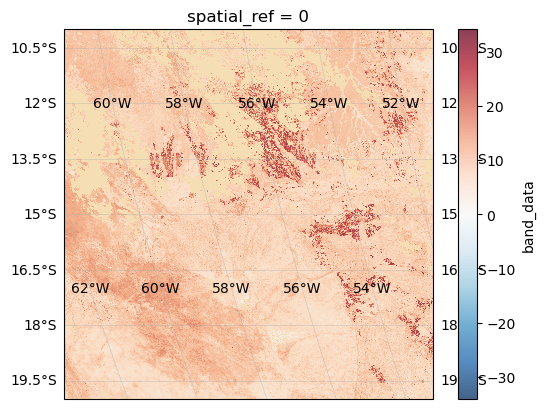

In [19]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

crs = ccrs.Sinusoidal.MODIS
ax = plt.axes(projection=crs)

ax.add_feature(cfeature.LAND, facecolor="wheat", zorder=0)
ds.sel(band=1, drop=True).band_data.plot.imshow(
    ax=ax, transform=crs, alpha=0.75, zorder=1
)
ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)

plt.show()

## Access multiple tiles

In [20]:
from datetime import date
from math import ceil, cos, floor, radians


def sen4gpp_urls(datum, bbox):
    ## Return Sen4GPP tile URLs for a lon/lat bounding box and date
    
    day = date.fromisoformat(datum)
    west, south, east, north = bbox

    if not (-180 <= west < east <= 180 and -90 <= south < north <= 90):
        raise ValueError(
            "Use (west, south, east, north) in degrees. "
            "Split boxes crossing the antimeridian into two."
        )

    latitudes = [south, north]
    if south < 0 < north:
        latitudes.append(0)

    h_edges = [
        18 + lon * cos(radians(lat)) / 10
        for lat in latitudes
        for lon in (west, east)
    ]
    h_start, h_stop = floor(min(h_edges)), ceil(max(h_edges))
    v_start, v_stop = floor((90 - north) / 10), ceil((90 - south) / 10)

    base = f"https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/sen4gpp/{day}"
    return [
        f"{base}/QISCARF_GPP_{day:%Y%m%d}_h{h:02d}v{v:02d}"
        "_m0.830_b0.053_pc31.000_qi0.080_v02.tif"
        for v in range(v_start, v_stop)
        for h in range(h_start, h_stop)
    ]

In [22]:
# area around the Med sea
west, east = -5.0, 37.0  
south, north = 28.0, 48.0

datum = '2020-04-06'

In [23]:
urls = sen4gpp_urls(datum, [west, south, east, north])

In [25]:
ds = xr.open_mfdataset(
    urls,
    engine="rasterio",
    combine="by_coords",
    chunks="auto",
    data_vars="minimal",
    coords="minimal",
    join="exact",
)

gpp = ds.band_data.sel(band=1, drop=True)

/tmp/ipykernel_11765/2504533448.py:1: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.open_mfdataset(
/tmp/ipykernel_11765/2504533448.py:1: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.open_mfdataset(
/tmp/ipykernel_11765/2504533448.py:1: FutureWarning: In a future version of xarray the default value for compat will cha

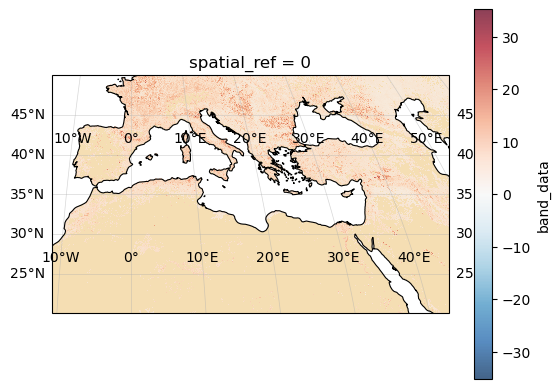

In [27]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

crs = ccrs.Sinusoidal.MODIS
ax = plt.axes(projection=crs)

ax.add_feature(cfeature.LAND, facecolor="wheat", zorder=0)
ds.sel(band=1, drop=True).band_data.plot.imshow(
    ax=ax, transform=crs, alpha=0.75, zorder=1
)
ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
ax.coastlines(resolution="50m", color="black", linewidth=0.8, zorder=2)

plt.show()